# Session 2 — Exploring Resolution and Intensity
**RGB, grayscale, histograms, normalization** · Computer Vision & Speech Recognition · Joshua Cole

Every exercise runs on a real MILK10k dermoscopic image, and every number quoted in the written answers is printed by a
code cell below it. Image **A** is a melanocytic nevus (Benign) and is used for the single-image exercises; image
**B** is a melanoma (Malignant) and only appears where two classes are compared.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "milk10k").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

from milk10k.data import IMAGE_DIR, PROJECT_ROOT

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# one lesion per row: lesion_id, derm_id (dermoscopic image id), diagnosis_1, dx, age, sex, site
lesions = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "lesions.csv")

# Two dermoscopic images from different diagnosis classes (picked once, from a random sample):
#   A = a melanocytic nevus (Benign)    B = a melanoma (Malignant)
IMG_A, IMG_B = "ISIC_2348795", "ISIC_6511897"
for iid in (IMG_A, IMG_B):
    row = lesions[lesions.derm_id == iid].iloc[0]
    print(f"{iid}: {row.dx:3s} ({row.diagnosis_1}), age {row.age:.0f}, {row.sex}")

def load(isic_id):
    return Image.open(IMAGE_DIR / f"{isic_id}.jpg")

ISIC_2348795: NV  (Benign), age 85, male
ISIC_6511897: MEL (Malignant), age 70, male


## 1. Pixels & Resolution

In [2]:
img = load(IMG_A)
arr = np.array(img)

print("PIL size (width, height) :", img.size)
print("NumPy shape (H, W, C)    :", arr.shape)
print("dtype                    :", arr.dtype)
print("value range in this image:", arr.min(), "to", arr.max(), "(a uint8 can hold 0 to 255)")
print("pixels (H x W)           :", f"{arr.shape[0]} x {arr.shape[1]} = {arr.shape[0] * arr.shape[1]:,}")
print("numbers in the array     :", f"{arr.size:,}")

PIL size (width, height) : (600, 450)
NumPy shape (H, W, C)    : (450, 600, 3)
dtype                    : uint8
value range in this image: 0 to 241 (a uint8 can hold 0 to 255)
pixels (H x W)           : 450 x 600 = 270,000
numbers in the array     : 810,000


**Spatial resolution.** The image is **450 × 600** (height × width): 450 rows and 600 columns of pixels, 270,000 pixels in
total. That number is how many samples of the scene the camera took, so it sets the finest detail the image can hold: nothing
smaller than one pixel can be seen, and a pigment dot or a vessel narrower than a pixel is averaged into its neighbours.
It is not a physical size: how much skin one pixel covers depends on the dermatoscope's field of view, which MILK10k's
metadata does not record.

**Shape.** `(450, 600, 3)`. NumPy indexes rows first, so height comes before width (PIL reports `size` the other way
round, `(600, 450)`). There are three numbers, not two, because each pixel is a colour: the last axis holds its red, green
and blue intensities. A grayscale image would need only two (`(450, 600)`).

**dtype.** `uint8`: an unsigned 8-bit integer, so every value is a whole number from 0 (no light) to 255 (full intensity).
This image uses 0 to 241, so nothing is clipped at white. Consequence to remember: arithmetic on `uint8` wraps around
(250 + 10 = 4), so convert to float before averaging channels, which exercise 3 does.

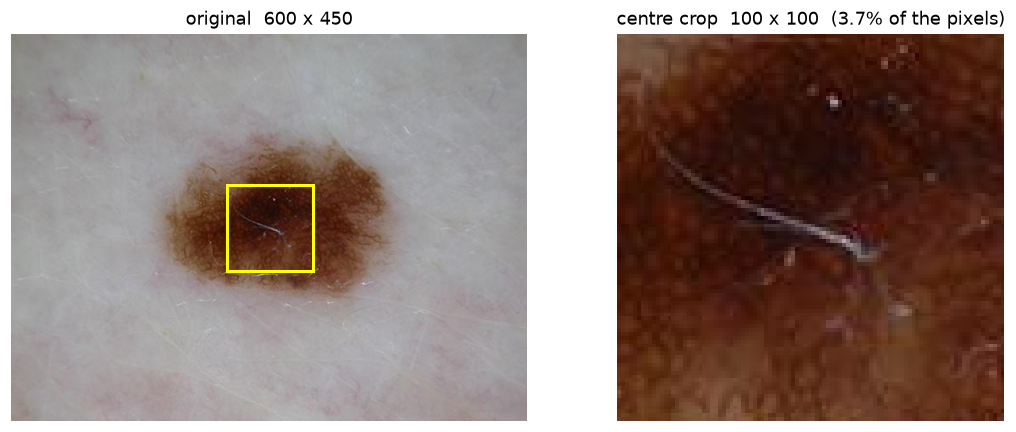

In [3]:
h, w, _ = arr.shape
r0, c0 = h // 2 - 50, w // 2 - 50
crop = arr[r0:r0 + 100, c0:c0 + 100]

fig, ax = plt.subplots(1, 2, figsize=(10, 4), gridspec_kw={"width_ratios": [w / h, 1]})
ax[0].imshow(arr); ax[0].set_title(f"original  {w} x {h}")
ax[0].add_patch(Rectangle((c0, r0), 100, 100, fill=False, edgecolor="yellow", lw=2))
ax[1].imshow(crop); ax[1].set_title(f"centre crop  100 x 100  ({100 * 100 / (h * w):.1%} of the pixels)")
for a in ax:
    a.axis("off")
plt.tight_layout(); plt.show()

**Crop: what is lost?** The crop keeps full pixel detail but only 3.7 % of the image: the lesion's outline, its overall
shape and symmetry, and the skin around it are gone, and what remains is local texture and colour. For diagnosis that
matters: dermatologists judge asymmetry, border and the distribution of colours across the *whole* lesion, so a 100 × 100
window can show a convincing patch of brown pigment (here with a hair across it) and still miss that the lesion is lopsided or has an irregular edge.

## 2. RGB Channels

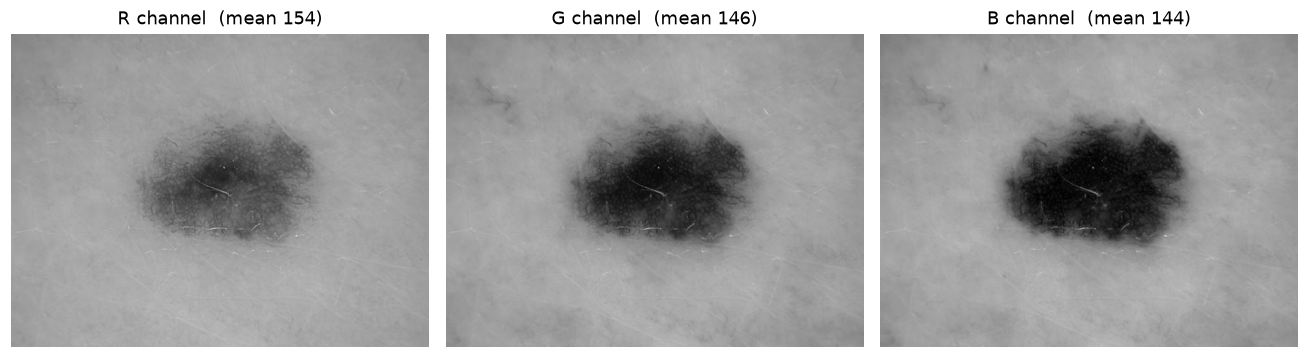

    lesion (centre)  skin (frame)    drop
R              76.8         158.0     51%
G              35.6         154.7     77%
B              20.8         155.4     87%


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
for i, name in enumerate("RGB"):
    ax[i].imshow(arr[:, :, i], cmap="gray", vmin=0, vmax=255)   # raw intensity, no colour tint
    ax[i].set_title(f"{name} channel  (mean {arr[:, :, i].mean():.0f})"); ax[i].axis("off")
plt.tight_layout(); plt.show()

# How strongly does the lesion stand out from the surrounding skin in each channel?
skin = np.ones((h, w), bool); skin[40:-40, 40:-40] = False        # a 40 px frame around the image
print(f"{'':3s}{'lesion (centre)':>16s}{'skin (frame)':>14s}{'drop':>8s}")
for i, name in enumerate("RGB"):
    ch = arr[:, :, i].astype(float)
    lesion_mean, skin_mean = ch[r0:r0 + 100, c0:c0 + 100].mean(), ch[skin].mean()
    print(f"{name:3s}{lesion_mean:16.1f}{skin_mean:14.1f}{1 - lesion_mean / skin_mean:8.0%}")

**Which channel carries the most signal?** Here the **blue** channel separates lesion from skin best: the centre drops by
87 % relative to the surrounding skin, against 77 % in green and only 51 % in red. Looking at the three images agrees: the
lesion is a near-black blob in blue, a little less so in green, and still clearly grey in red, which is the flattest of the
three. The reason is the pigment: melanin absorbs short wavelengths strongly and red light much less, so brown pigment is
darkest in blue and green while healthy skin stays bright in all three. The caveat is that this is one nevus on pale skin;
a pink, non-pigmented lesion (e.g. many basal cell carcinomas) would show far less contrast in every channel, and red is
where its vessels would show.

## 3. Grayscale Conversion

max pixel difference : 6.95   (mean 0.84)
worst pixel (row 193, col 221) has RGB (102, 68, 31): naive 67.0 vs luminosity 73.9
luminosity vs PIL's convert('L'): max |difference| 0.49 (rounding only)


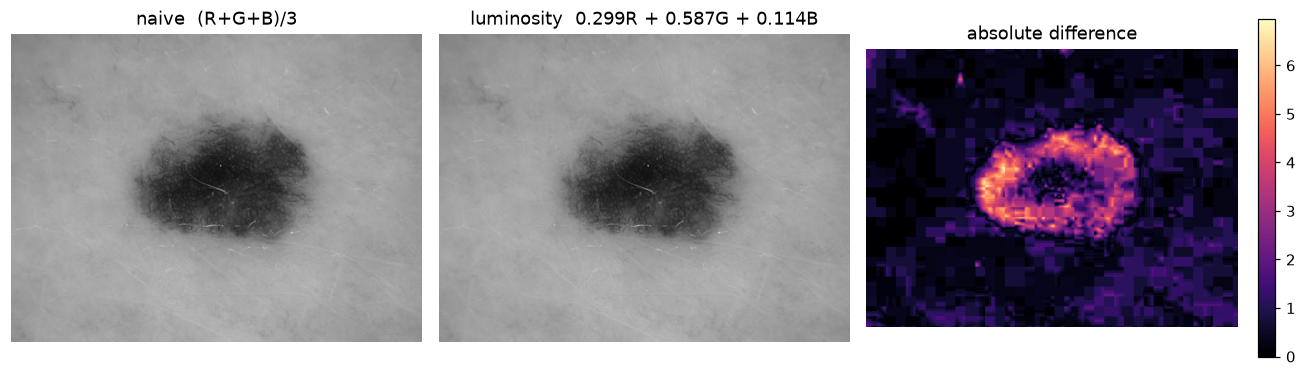

In [5]:
f = arr.astype(np.float64)        # float first: uint8 sums wrap around at 256
R, G, B = f[..., 0], f[..., 1], f[..., 2]

naive = (R + G + B) / 3
lumin = 0.299 * R + 0.587 * G + 0.114 * B

diff = np.abs(naive - lumin)
iy, ix = np.unravel_index(diff.argmax(), diff.shape)
print(f"max pixel difference : {diff.max():.2f}   (mean {diff.mean():.2f})")
print(f"worst pixel (row {iy}, col {ix}) has RGB {tuple(int(v) for v in arr[iy, ix])}: naive {naive[iy, ix]:.1f} vs luminosity {lumin[iy, ix]:.1f}")
print(f"luminosity vs PIL's convert('L'): max |difference| {np.abs(np.array(img.convert('L')) - lumin).max():.2f} (rounding only)")

fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
ax[0].imshow(naive, cmap="gray", vmin=0, vmax=255); ax[0].set_title("naive  (R+G+B)/3")
ax[1].imshow(lumin, cmap="gray", vmin=0, vmax=255); ax[1].set_title("luminosity  0.299R + 0.587G + 0.114B")
im = ax[2].imshow(diff, cmap="magma"); ax[2].set_title("absolute difference")
fig.colorbar(im, ax=ax[2], fraction=0.046)
for a in ax:
    a.axis("off")
plt.tight_layout(); plt.show()

**Why they disagree.** The naive average treats red, green and blue as equally bright. The luminosity formula weights them
by how bright each colour looks to a human eye: green counts for 58.7 %, red for 29.9 % and blue for only 11.4 %. The two
therefore agree on any pixel where R, G and B are close (grey skin) and differ most where the channels are far apart. The
largest gap is **about 7 grey levels out of 255** (at a saturated brown pixel, RGB 102/68/31, where the average gives 67 and the
luminosity 74), so on this image the visible difference is small, concentrated on the pigmented lesion. **The luminosity
formula matches human perception better**, because the eye is most sensitive to green and least to blue; it is also the
conversion that `PIL.Image.convert("L")` uses, which the check above confirms to within rounding.

## 4. Histograms

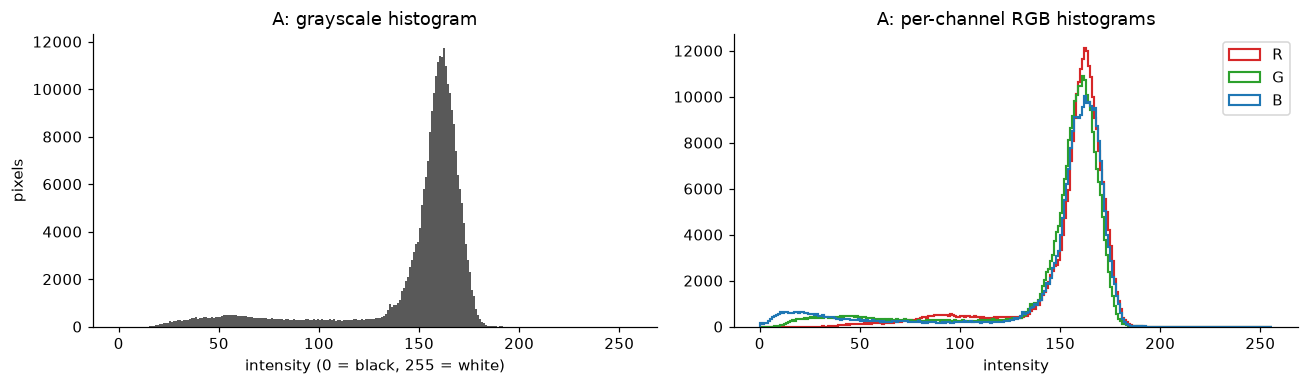

In [6]:
gray = lumin.round().astype(np.uint8)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].hist(gray.ravel(), bins=256, range=(0, 256), color="0.35")
ax[0].set_title("A: grayscale histogram"); ax[0].set_xlabel("intensity (0 = black, 255 = white)"); ax[0].set_ylabel("pixels")

for i, (name, col) in enumerate(zip("RGB", ("tab:red", "tab:green", "tab:blue"))):
    ax[1].hist(arr[:, :, i].ravel(), bins=256, range=(0, 256), histtype="step", color=col, lw=1.4, label=name)
ax[1].set_title("A: per-channel RGB histograms"); ax[1].set_xlabel("intensity"); ax[1].legend()
plt.tight_layout(); plt.show()

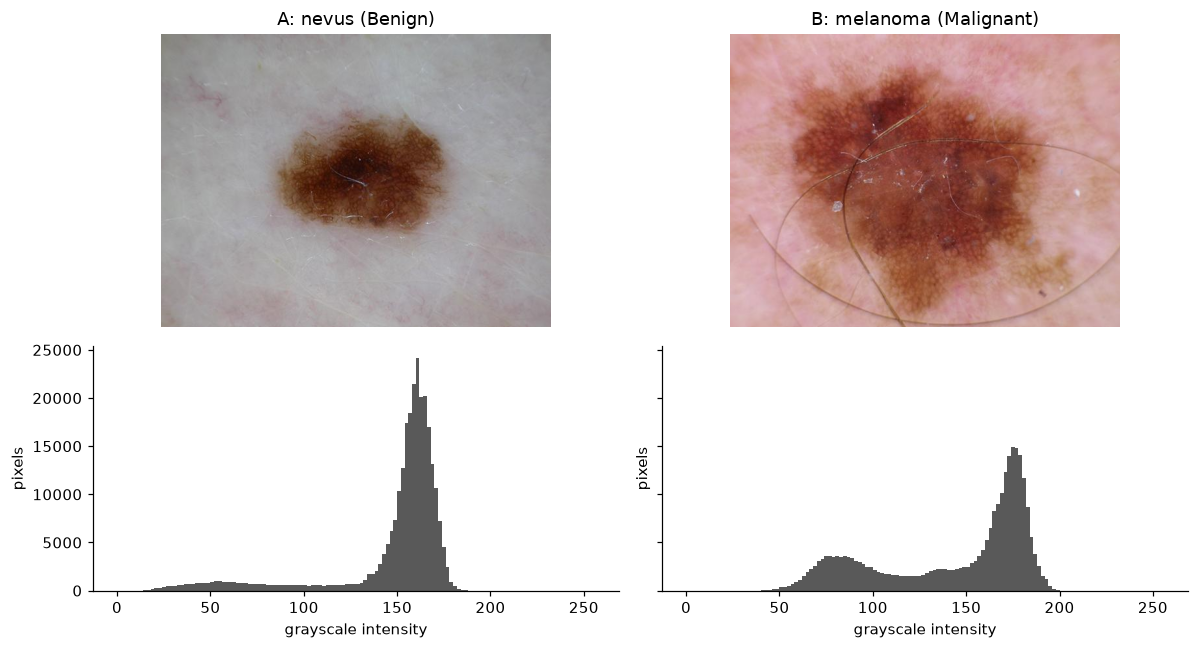

                               A (nevus)  B (melanoma)
mean                              148.03        143.68
std                                32.35         40.06
5th percentile                     58.93         70.75
95th percentile                   172.63        184.67
share of pixels < 100               0.10          0.23
dark peak (grey level < 120)       54.00         82.00
bright peak (>= 120)              162.00        178.00


In [7]:
def to_gray(a):
    f_ = a.astype(np.float64)
    return 0.299 * f_[..., 0] + 0.587 * f_[..., 1] + 0.114 * f_[..., 2]

arr_b = np.array(load(IMG_B))
gA, gB = to_gray(arr), to_gray(arr_b)

fig, ax = plt.subplots(2, 2, figsize=(11, 6), sharey="row", gridspec_kw={"height_ratios": [1.2, 1]})
for j, (a, g, title) in enumerate(((arr, gA, "A: nevus (Benign)"), (arr_b, gB, "B: melanoma (Malignant)"))):
    ax[0, j].imshow(a); ax[0, j].set_title(title); ax[0, j].axis("off")
    ax[1, j].hist(g.ravel(), bins=128, range=(0, 256), color="0.35")
    ax[1, j].set_xlabel("grayscale intensity"); ax[1, j].set_ylabel("pixels")
plt.tight_layout(); plt.show()

def mode(g, lo, hi):          # most common grey level (4-level bins) inside [lo, hi)
    counts, edges = np.histogram(g, bins=np.arange(lo, hi + 1, 4))
    return edges[counts.argmax()] + 2

print(f"{'':28s}{'A (nevus)':>12s}{'B (melanoma)':>14s}")
for label, fn in (("mean", np.mean), ("std", np.std), ("5th percentile", lambda g: np.percentile(g, 5)),
                  ("95th percentile", lambda g: np.percentile(g, 95)), ("share of pixels < 100", lambda g: (g < 100).mean()),
                  ("dark peak (grey level < 120)", lambda g: mode(g, 0, 120)), ("bright peak (>= 120)", lambda g: mode(g, 120, 256))):
    print(f"{label:28s}{fn(gA):12.2f}{fn(gB):14.2f}")

**Do the histograms differ?** Yes, clearly. The nevus (A) has one dominant peak of bright skin at about 162 and only a low
shoulder of dark pixels (10 % of its pixels are below 100). The melanoma (B) is **bimodal**: a dark peak at about 82 (the
lesion) almost as tall as a bright peak at about 178 (the skin), with 23 % of pixels below 100 and a standard deviation of 40
against 32. The most likely explanation is **lesion size**: B's lesion fills much of the frame, while A's is a small blob on
a large area of skin, so B simply has far more dark pixels. Two other factors I cannot rule out from two images: **skin tone
and exposure** (B's skin is pinker and its bright peak sits 16 grey levels higher, 178 against 162) and **lighting /
camera**, since MILK10k's dermoscopic images come from different clinics and devices. So the shape difference here says more
about framing and acquisition than about the diagnosis, and two images prove nothing about the classes.

## 5. Normalization

raw     : min    0.00  max  241.00  mean  147.99  std  34.57
min-max : min   0.000  max   0.945  mean   0.580  std  0.136
z-score : min  -4.281  max   2.691  mean   0.000  std  1.000


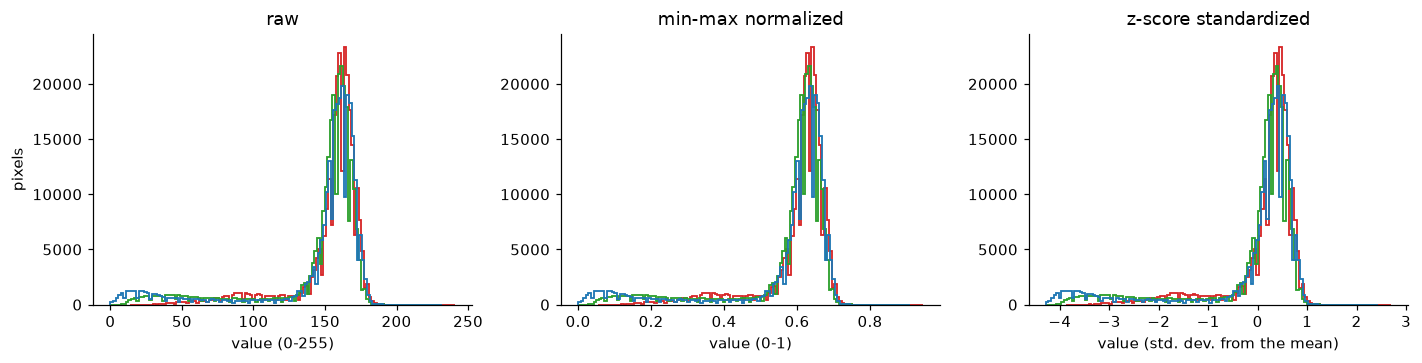

In [8]:
x = arr.astype(np.float64)

# min-max: with the known range of a uint8 image this is simply x / 255, mapping [0, 255] -> [0.0, 1.0]
minmax = (x - 0) / (255 - 0)

# z-score: subtract the mean, divide by the standard deviation (here over all pixels and channels of this image)
zscore = (x - x.mean()) / x.std()

print(f"raw     : min {x.min():7.2f}  max {x.max():7.2f}  mean {x.mean():7.2f}  std {x.std():6.2f}")
print(f"min-max : min {minmax.min():7.3f}  max {minmax.max():7.3f}  mean {minmax.mean():7.3f}  std {minmax.std():6.3f}")
print(f"z-score : min {zscore.min():7.3f}  max {zscore.max():7.3f}  mean {zscore.mean():7.3f}  std {zscore.std():6.3f}")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
for a, data, title, xl in ((ax[0], x, "raw", "value (0-255)"),
                           (ax[1], minmax, "min-max normalized", "value (0-1)"),
                           (ax[2], zscore, "z-score standardized", "value (std. dev. from the mean)")):
    for i, col in enumerate(("tab:red", "tab:green", "tab:blue")):
        a.hist(data[:, :, i].ravel(), bins=128, histtype="step", color=col, lw=1.2)
    a.set_title(title); a.set_xlabel(xl)
ax[0].set_ylabel("pixels")
plt.tight_layout(); plt.show()

**What changed, and what did not.** All three histograms have exactly the same shape: normalization only rescales the
x-axis. Min-max squeezes 0 to 255 into 0 to 1 (mean 0.58); z-score re-centres the data on 0 with unit spread (range
-4.3 to +2.7 here).

**Which for a neural network?** I would feed in the **z-score** version (or min-max at the least), with the mean and standard
deviation computed once on the *training set* and reused for validation and test, rather than per image. Networks start from
small random weights and learn by gradient descent; with raw values up to 255 the first layer's outputs are huge and saturate
activations such as sigmoid or tanh, gradients vanish or explode and the learning rate has to be tiny. Inputs centred near 0
with a similar scale in every channel keep the loss surface well-conditioned, so training is faster and more stable.